In [82]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import datasets

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix,ConfusionMatrixDisplay

from mpl_toolkits.mplot3d import Axes3D
from sklearn.linear_model import LogisticRegression

In [75]:
df=pd.read_csv(r"input\breast_cancer_mod.csv")
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,0,0,0,0,0,0,0,0,0,1,...,0,0,0,1,1,0,0,1,1,0
1,0,1,0,1,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,1,0
2,0,1,0,0,0,0,0,0,0,1,...,1,0,1,0,1,1,0,1,1,0
3,0,1,0,0,0,0,0,0,0,1,...,1,0,0,0,0,0,0,1,1,0
4,0,0,0,1,0,0,0,0,0,0,...,0,0,1,0,0,0,0,1,1,0


In [76]:
X=df.drop('target', axis=1)
y=df['target']
X['sum_weights']=X.sum(axis=1)

In [77]:
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=24,test_size=0.25,stratify=y)

In [78]:
max_score,threshold=-1,0
for i in range(len(X.columns)):

    X_train['pred']= X_train['sum_weights']>=i

    if max_score<accuracy_score(y_train,X_train['pred']):

        max_score=accuracy_score(y_train,X_train['pred'])

        threshold=i

    

In [79]:
max_score,threshold

(0.8474178403755869, 27)

In [80]:
accuracy_score(y_test,X_test['sum_weights']>=threshold)

0.8741258741258742

In [85]:
cm=confusion_matrix(y_test,X_test['sum_weights']>=threshold)

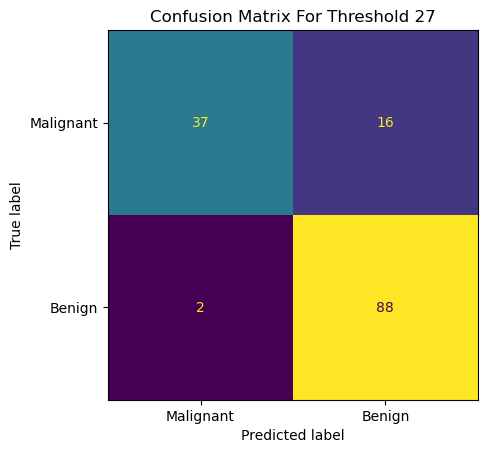

In [87]:
disp = ConfusionMatrixDisplay(cm, display_labels = ['Malignant','Benign'])
disp.plot(colorbar=False)
plt.title(f'Confusion Matrix For Threshold {threshold}')
plt.grid(False)